# 08 · Coverage proxies across rural, vulnerable and tribal tracts

The equity question, asked with observable proxies: how do road density, POIs per building, buildings per housing unit and the Microsoft share differ between urban and rural, low and high vulnerability, and tribal and other tracts, and how much of any gap is explained by where those tracts are.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "data").exists())
DATA, OUT, ANALYSIS = ROOT / "data", ROOT / "eda_outputs", ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "axes.titlesize": 11, "axes.labelsize": 9})
REG = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
NAME = {"maricopa-az": "Maricopa AZ", "northern-ca": "Northern CA", "eastern-ok": "Eastern OK", "south-central-tx": "S-C Texas", "eastern-wa": "Eastern WA"}
COL = dict(zip(REG, ["#e07b39", "#c0504d", "#6a9e4f", "#3b6fb6", "#8e6bbf"]))
df = pd.read_parquet(OUT / "base_table.parquet")

def box_by_region(ax, col, log=False, title="", ylabel=None, data=None):
    d = df if data is None else data
    vals = [d.loc[d.region == r, col].dropna() for r in REG]
    if log: vals = [np.log10(v[v > 0]) for v in vals]
    bp = ax.boxplot(vals, patch_artist=True, medianprops=dict(color="k"), flierprops=dict(marker=".", markersize=2, alpha=.3))
    for patch, r in zip(bp["boxes"], REG): patch.set_facecolor(COL[r]); patch.set_alpha(.75)
    ax.set_xticks(range(1, 6)); ax.set_xticklabels([f"{NAME[r]}\nn={len(v):,}" for r, v in zip(REG, vals)], fontsize=7.5)
    ax.set_title(title); ax.set_ylabel(ylabel or (("log10 " if log else "") + col))

def n_outliers(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); k = 1.5 * (q3 - q1)
    return int(((s < q1 - k) | (s > q3 + k)).sum())

def heat(ax, M, fmt="{:.2f}", cmap="RdBu_r", vmin=-1, vmax=1, fs=7, rot=60):
    im = ax.imshow(M.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=rot, ha="right", fontsize=8)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index, fontsize=8)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]; ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fs, color="k" if abs(v - (vmin + vmax) / 2) < (vmax - vmin) * .35 else "w")
    return im

## 1. Coverage proxies
The hidden target cannot be computed, so we describe coverage with observable stand-ins. Each is a different angle on 'how well mapped is this tract'; none is the target.

In [2]:
import statsmodels.api as sm, statsmodels.formula.api as smf
df["ruca_grp"] = pd.cut(df.ruca_primary, [0, 3, 6, 9, 10], labels=["metro (1-3)", "micro (4-6)", "small town (7-9)", "rural (10)"])
df["svi_q"] = pd.qcut(df.svi_overall, 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"]); df["cvi_q"] = pd.qcut(df.cvi_overall, 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
df["has_hwy"] = df.road_km_hwy > 0; df["has_fire"] = df.poi_n_fire > 0
P = {"poi_per_100_bldg": "POIs per 100 buildings", "road_km_per_km2": "road km per km2", "bldg_per_hu": "buildings per housing unit", "share_msft": "Microsoft share of buildings", "has_fire": "fire POI present"}
print(pd.DataFrame({"what it measures": ["places relative to buildings", "road network density", "building count vs ACS homes", "how much of the building set is Microsoft footprints", "facility presence"]}, index=list(P)).to_string())
print("\ndescribe:"); print(df[list(P)].astype(float).describe().T[["count", "mean", "50%", "std"]].round(2).to_string())

                                                      what it measures
poi_per_100_bldg                          places relative to buildings
road_km_per_km2                                   road network density
bldg_per_hu                                building count vs ACS homes
share_msft        how much of the building set is Microsoft footprints
has_fire                                             facility presence

describe:
                   count   mean   50%    std
poi_per_100_bldg  9792.0  20.17  7.84  65.16
road_km_per_km2   9792.0   8.15  8.74   4.95
bldg_per_hu       9712.0   1.26  1.07   2.53
share_msft        9792.0   0.38  0.17   0.38
has_fire          9794.0   0.29  0.00   0.46


**Takeaway:** five proxies are used, each a different view of coverage: places per building, road density, buildings per ACS home, the Microsoft share of buildings (how much of the likely reference is already in Overture) and whether a fire POI exists. Their medians are 7.8 POIs per 100 buildings, 8.7 road km/km2, 1.07 buildings per home and a Microsoft share of 0.17, with fire POIs present in 29% of tracts.

## 2. By urban / rural and RUCA

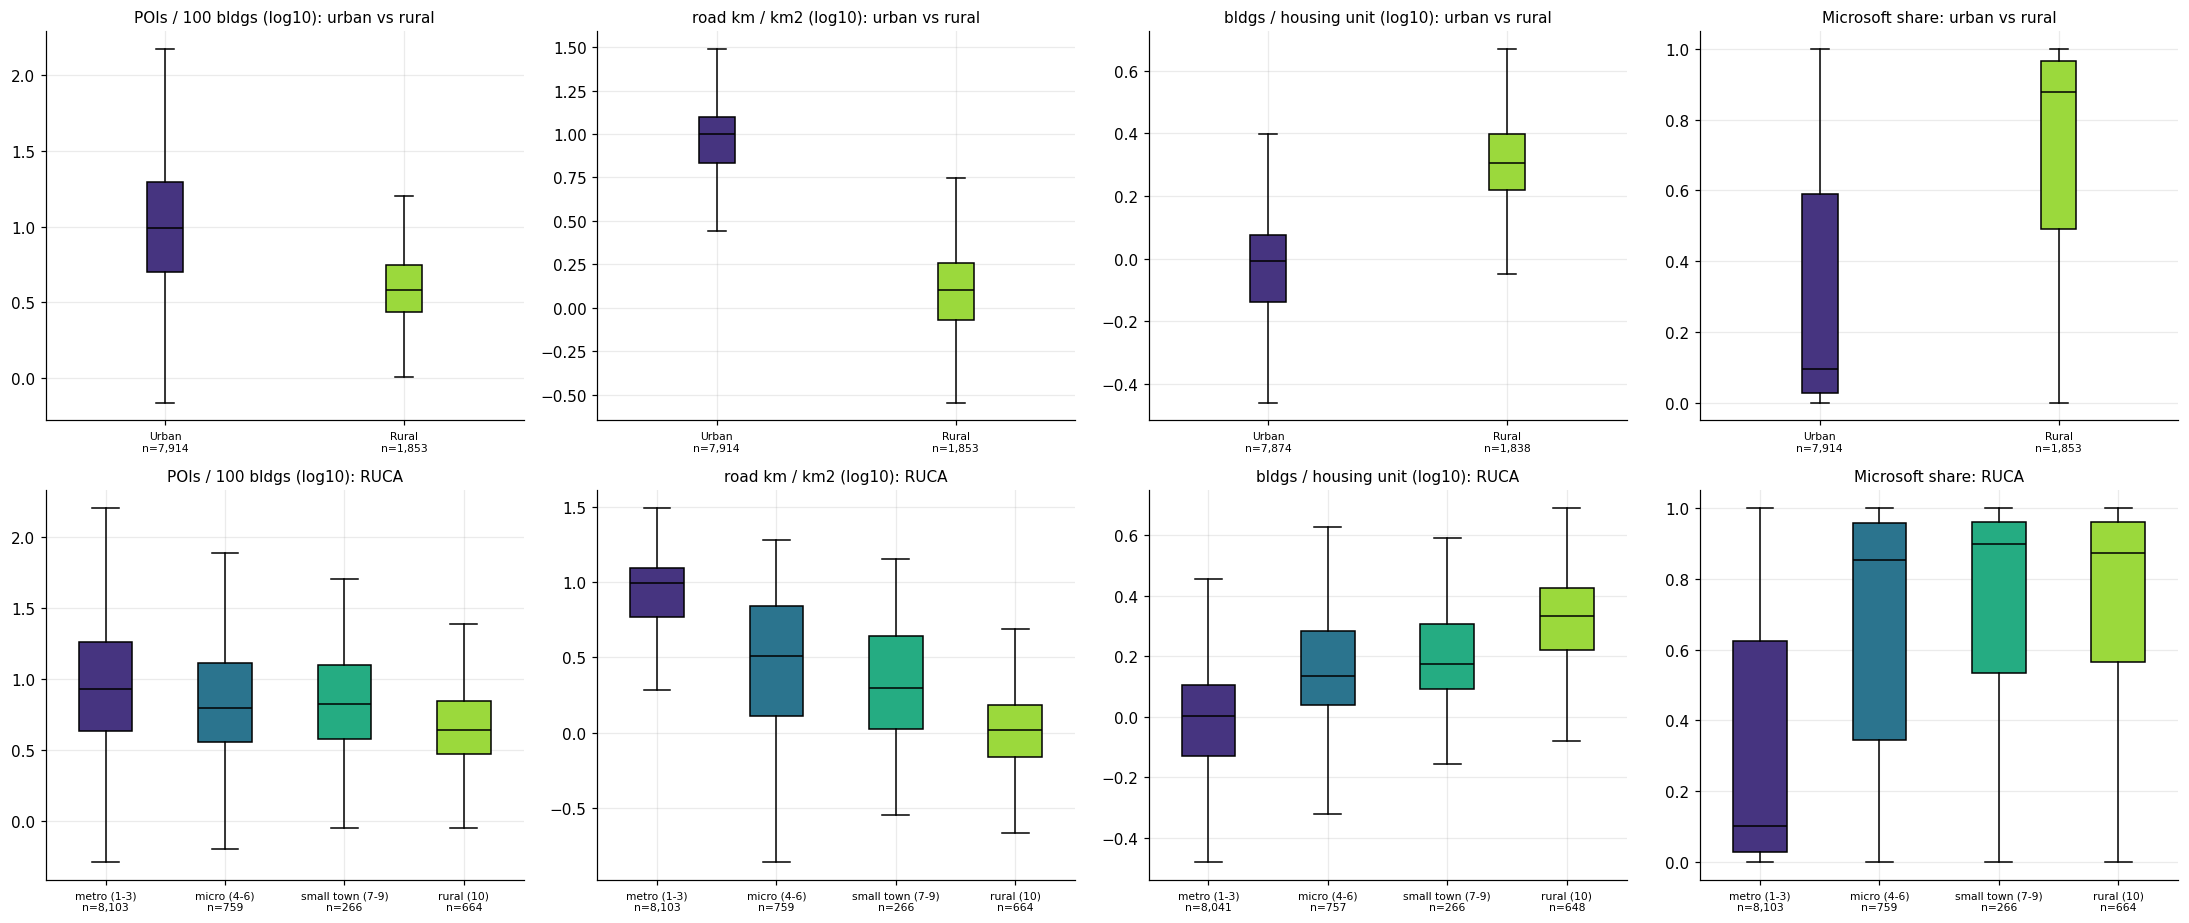

          poi_per_100_bldg  road_km_per_km2  bldg_per_hu  share_msft
ur_class                                                            
Rural                 3.84             1.27         2.03        0.88
Urban                 9.78            10.03         0.98        0.09

                  poi_per_100_bldg  road_km_per_km2  bldg_per_hu  share_msft
ruca_grp                                                                    
metro (1-3)                   8.54             9.79         1.00        0.10
micro (4-6)                   6.27             3.21         1.36        0.85
small town (7-9)              6.69             1.97         1.49        0.90
rural (10)                    4.40             1.04         2.14        0.87

fire POI present, urban vs rural (%): {'Rural': 54.3, 'Urban': 23.6}


In [3]:
def gbox(ax, col, by, order, title, data=None, log=True, pct=False):
    d = df if data is None else data; v = []
    for g in order:
        x = d.loc[d[by] == g, col].dropna().astype(float); v.append(np.log10(x[x > 0]) if log else x)
    bp = ax.boxplot(v, patch_artist=True, showfliers=False, medianprops=dict(color="k"))
    for p_, c in zip(bp["boxes"], plt.cm.viridis(np.linspace(.15, .85, len(order)))): p_.set_facecolor(c)
    ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels([f"{g}\nn={len(x):,}" for g, x in zip(order, v)], fontsize=7); ax.set_title(title, fontsize=10)
fig, ax = plt.subplots(2, 4, figsize=(20, 8.5)); items = [("poi_per_100_bldg", "POIs / 100 bldgs (log10)", True), ("road_km_per_km2", "road km / km2 (log10)", True), ("bldg_per_hu", "bldgs / housing unit (log10)", True), ("share_msft", "Microsoft share", False)]
for j, (c, t_, lg) in enumerate(items): gbox(ax[0, j], c, "ur_class", ["Urban", "Rural"], t_ + ": urban vs rural", log=lg); gbox(ax[1, j], c, "ruca_grp", ["metro (1-3)", "micro (4-6)", "small town (7-9)", "rural (10)"], t_ + ": RUCA", log=lg)
plt.tight_layout(); plt.show()
print(df.groupby("ur_class")[["poi_per_100_bldg", "road_km_per_km2", "bldg_per_hu", "share_msft"]].median().round(2).to_string()); print(); print(df.groupby("ruca_grp")[["poi_per_100_bldg", "road_km_per_km2", "bldg_per_hu", "share_msft"]].median().round(2).to_string())
print("\nfire POI present, urban vs rural (%):", (df.groupby("ur_class").has_fire.mean() * 100).round(1).to_dict())

**Takeaway:** the urban-rural split is large on every proxy. Rural tracts have 1.3 road km/km2 vs 10.0 in urban ones, 3.8 vs 9.8 POIs per 100 buildings, 2.0 vs 1.0 buildings per housing unit, and a Microsoft share of 0.88 vs 0.09. Along the RUCA ladder the step is between metro and everything else: micro, small-town and rural tracts all have Microsoft shares of 0.85-0.90, and road density falls steadily from 9.8 to 1.0. Fire POIs are more common in rural tracts (54% vs 24%) most likely because those tracts are larger.

## 3. By social and climate vulnerability

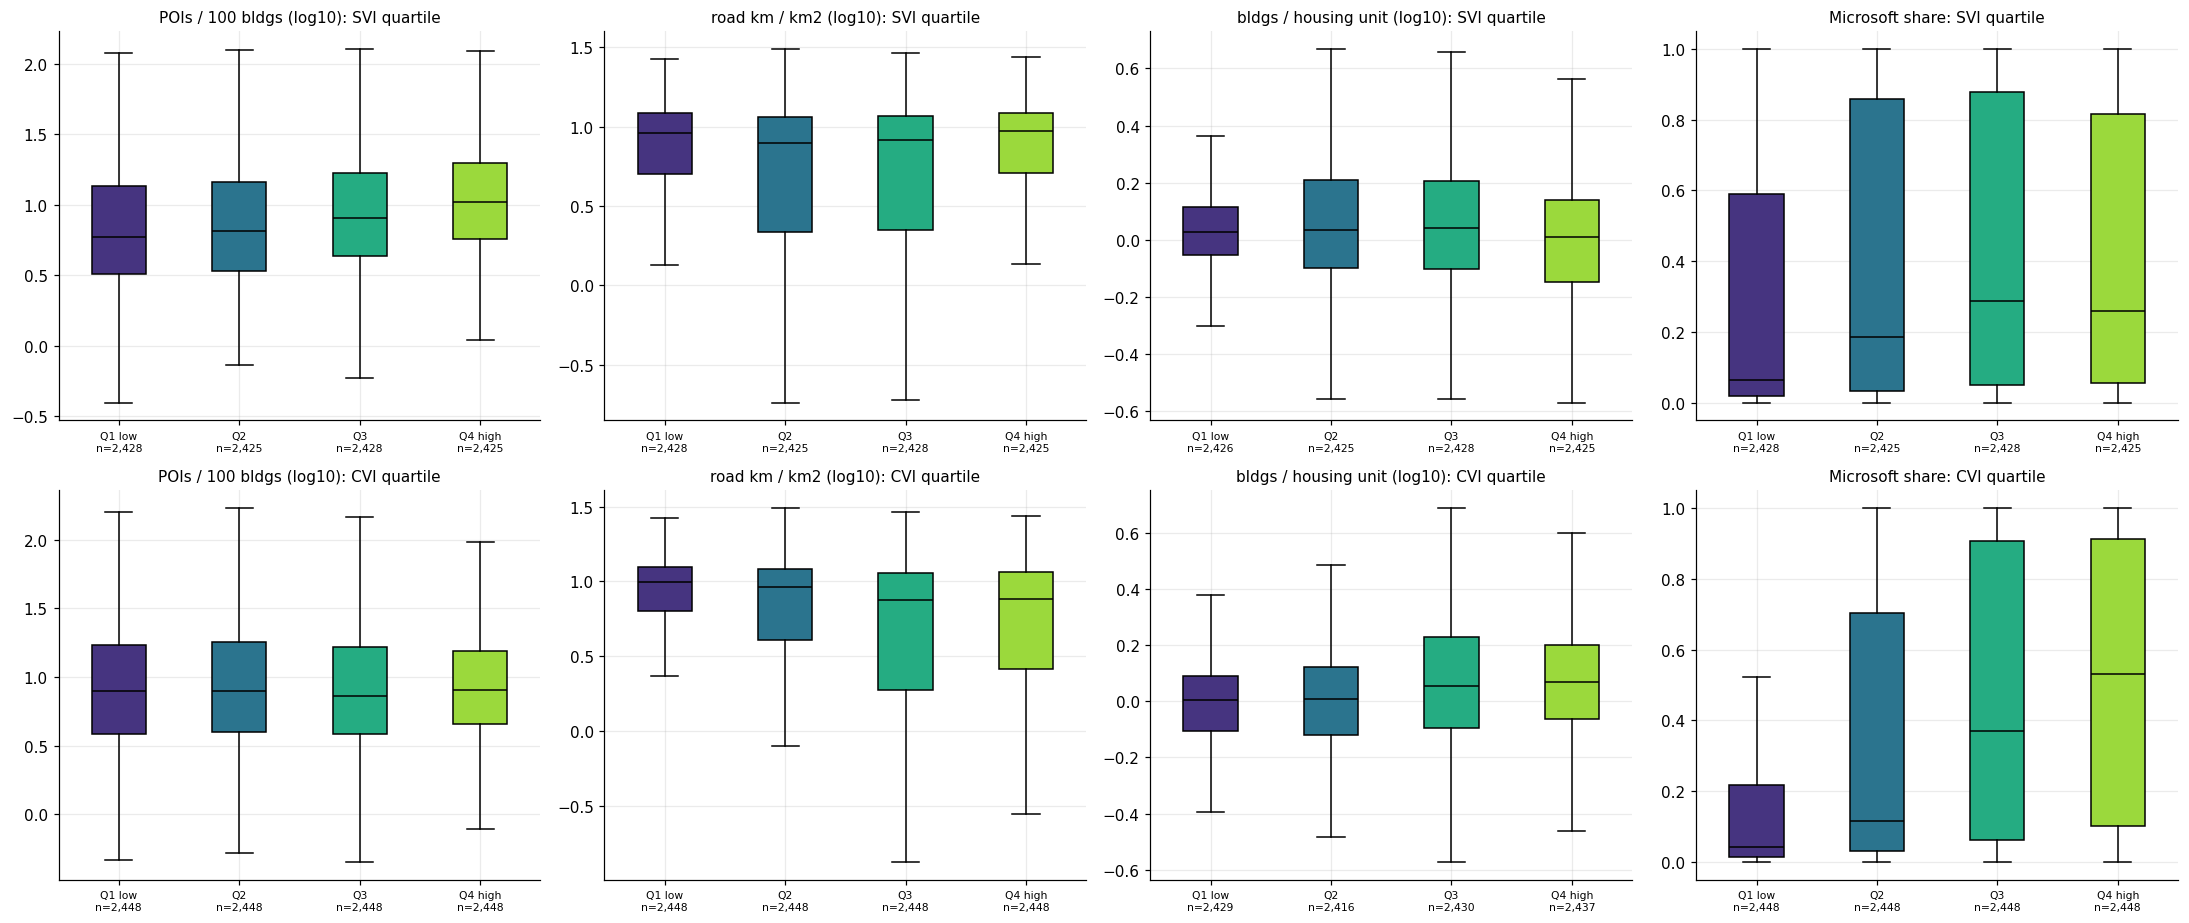

         poi_per_100_bldg  road_km_per_km2  bldg_per_hu  share_msft
svi_q                                                              
Q1 low               5.95             9.12         1.07        0.06
Q2                   6.50             7.86         1.08        0.18
Q3                   8.06             8.24         1.10        0.29
Q4 high             10.52             9.43         1.02        0.26

           proxy  Spearman vs SVI  Spearman vs CVI
poi_per_100_bldg             0.20             0.01
 road_km_per_km2             0.02            -0.14
     bldg_per_hu            -0.06             0.16
      share_msft             0.16             0.37

% with fire POI by SVI quartile: {'Q1 low': 25.4, 'Q2': 32.4, 'Q3': 32.5, 'Q4 high': 27.7}


In [4]:
fig, ax = plt.subplots(2, 4, figsize=(20, 8.5))
for j, (c, t_, lg) in enumerate(items): gbox(ax[0, j], c, "svi_q", ["Q1 low", "Q2", "Q3", "Q4 high"], t_ + ": SVI quartile", log=lg); gbox(ax[1, j], c, "cvi_q", ["Q1 low", "Q2", "Q3", "Q4 high"], t_ + ": CVI quartile", log=lg)
plt.tight_layout(); plt.show()
print(df.groupby("svi_q")[["poi_per_100_bldg", "road_km_per_km2", "bldg_per_hu", "share_msft"]].median().round(2).to_string()); print()
rows = []
for c in ["poi_per_100_bldg", "road_km_per_km2", "bldg_per_hu", "share_msft"]:
    x = df[["svi_overall", "cvi_overall", c]].dropna(); rows.append((c, stats.spearmanr(x.svi_overall, x[c])[0], stats.spearmanr(x.cvi_overall, x[c])[0]))
print(pd.DataFrame(rows, columns=["proxy", "Spearman vs SVI", "Spearman vs CVI"]).round(2).to_string(index=False))
print("\n% with fire POI by SVI quartile:", (df.groupby("svi_q").has_fire.mean() * 100).round(1).to_dict())

**Takeaway:** vulnerability matters much less than rurality. Road density and buildings per home hardly change across SVI quartiles (Spearman 0.02 and -0.06). POIs per 100 buildings rise with SVI (0.20, median 6.0 in the lowest quartile to 10.5 in the highest), the opposite of what an under-coverage story would predict for the most vulnerable tracts on this proxy. The Microsoft share rises with climate vulnerability (Spearman 0.37 with CVI), though this was not separated from region or rurality. Fire-POI presence is flat across SVI quartiles (25-33%).

## 4. Tribal versus non-tribal
One region at a time, so that region is not mixed in: 92% of tribal tracts are in Eastern Oklahoma.

                      n tribal  n other   diff  ci_lo  ci_hi  Cohen d  Welch p  Mann-Whitney p
proxy                                                                                         
POIs / 100 bldgs           805      387 -0.192 -0.246 -0.137   -0.442      0.0             0.0
road km / km2              805      387 -0.357 -0.399 -0.315   -0.987      0.0             0.0
bldgs / housing unit       803      379  0.086  0.059  0.114    0.386      0.0             0.0
Microsoft share            805      387  0.503  0.463  0.543    1.610      0.0             0.0

no-fire share: tribal 0.58 vs other 0.76 | chi-square p = 0.000


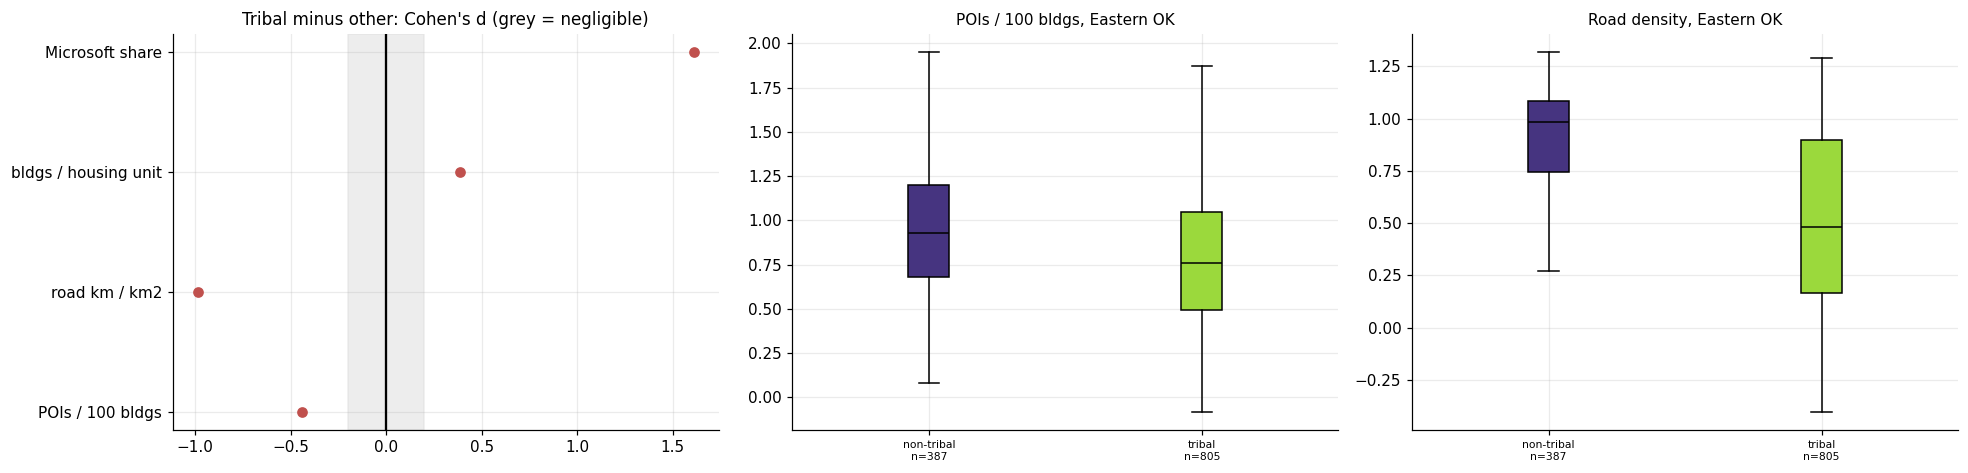

In [5]:
ok = df[df.region == "eastern-ok"].copy(); res = []
for c, nm in [("poi_per_100_bldg", "POIs / 100 bldgs"), ("road_km_per_km2", "road km / km2"), ("bldg_per_hu", "bldgs / housing unit"), ("share_msft", "Microsoft share")]:
    a, b = ok.loc[ok.tribal, c].dropna(), ok.loc[~ok.tribal, c].dropna()
    if c != "share_msft": a, b = np.log10(a[a > 0]), np.log10(b[b > 0])
    t, p = stats.ttest_ind(a, b, equal_var=False); u, pu = stats.mannwhitneyu(a, b); d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2); se = np.sqrt(a.var() / len(a) + b.var() / len(b)); diff = a.mean() - b.mean()
    res.append((nm, len(a), len(b), diff, diff - 1.96 * se, diff + 1.96 * se, d, p, pu))
R = pd.DataFrame(res, columns=["proxy", "n tribal", "n other", "diff", "ci_lo", "ci_hi", "Cohen d", "Welch p", "Mann-Whitney p"]).set_index("proxy"); print(R.round(3).to_string())
ct = pd.crosstab(ok.tribal, ~ok.has_fire); print("\nno-fire share: tribal", round(1 - ok[ok.tribal].has_fire.mean(), 2), "vs other", round(1 - ok[~ok.tribal].has_fire.mean(), 2), "| chi-square p =", f"{stats.chi2_contingency(ct)[1]:.3f}")
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4)); ax[0].errorbar(R["Cohen d"], range(len(R)), fmt="o", color="#c0504d"); ax[0].axvline(0, color="k"); ax[0].axvspan(-.2, .2, color="#ddd", alpha=.5); ax[0].set_yticks(range(len(R))); ax[0].set_yticklabels(R.index); ax[0].set_title("Tribal minus other: Cohen's d (grey = negligible)")
gbox(ax[1], "poi_per_100_bldg", "grp", ["non-tribal", "tribal"], "POIs / 100 bldgs, Eastern OK", data=ok.assign(grp=np.where(ok.tribal, "tribal", "non-tribal"))); gbox(ax[2], "road_km_per_km2", "grp", ["non-tribal", "tribal"], "Road density, Eastern OK", data=ok.assign(grp=np.where(ok.tribal, "tribal", "non-tribal")))
plt.tight_layout(); plt.show()

**Takeaway:** in Eastern Oklahoma, tribal tracts differ clearly from the others on every proxy: lower road density (diff -0.36 in log10, Cohen's d -0.99), fewer POIs per building (-0.19, d -0.44), slightly more buildings per home (+0.09, d 0.39) and a far higher Microsoft share (+0.50, d 1.61). They are also less likely to lack a fire POI (58% have none vs 76% of other tracts, p < 0.001), consistent with their larger area. All differences are significant, but the effect sizes are only large for road density and the Microsoft share.

## 5. Is the tribal gap just rurality? Stratify, then adjust

mean log POIs/100 bldgs by rural x tribal (Eastern OK):
        mean        size      
tribal False True  False True 
rural                         
False   2.29  2.29   343   428
True    1.32  1.30    35   375

                          tribal effect  ci_lo  ci_hi      p
unadjusted                      -0.371 -0.484 -0.259  0.000
+ rural                         -0.003 -0.110  0.104  0.957
+ rural + density                0.048 -0.059  0.156  0.380
+ rural + density + SVI         -0.018 -0.124  0.088  0.737


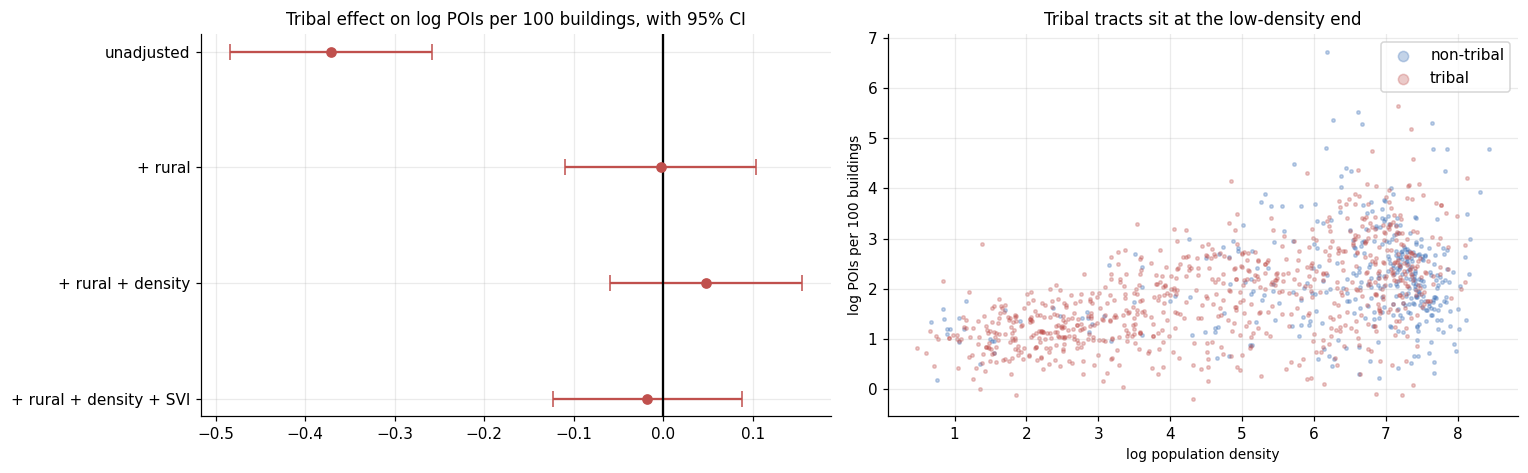

In [6]:
ok["y"] = np.log(ok.poi_per_100_bldg.replace(0, np.nan)); ok["lden"] = np.log1p(ok.pop_density); ok["rural_i"] = ok.rural.astype(int); ok["tribal_i"] = ok.tribal.astype(int); o = ok.dropna(subset=["y", "lden", "svi_overall"])
by = o.groupby(["rural", "tribal"]).y.agg(["mean", "size"]).unstack("tribal"); print("mean log POIs/100 bldgs by rural x tribal (Eastern OK):"); print(by.round(2).to_string())
m0 = smf.ols("y ~ tribal_i", o).fit(); m1 = smf.ols("y ~ tribal_i + rural_i", o).fit(); m2 = smf.ols("y ~ tribal_i + rural_i + lden", o).fit(); m3 = smf.ols("y ~ tribal_i + rural_i + lden + svi_overall", o).fit()
E = pd.DataFrame({"tribal effect": [m.params["tribal_i"] for m in (m0, m1, m2, m3)], "ci_lo": [m.conf_int().loc["tribal_i", 0] for m in (m0, m1, m2, m3)], "ci_hi": [m.conf_int().loc["tribal_i", 1] for m in (m0, m1, m2, m3)], "p": [m.pvalues["tribal_i"] for m in (m0, m1, m2, m3)]}, index=["unadjusted", "+ rural", "+ rural + density", "+ rural + density + SVI"]); print("\n", E.round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4)); ax[0].errorbar(E["tribal effect"], range(4), xerr=[E["tribal effect"] - E.ci_lo, E.ci_hi - E["tribal effect"]], fmt="o", capsize=5, color="#c0504d"); ax[0].axvline(0, color="k"); ax[0].set_yticks(range(4)); ax[0].set_yticklabels(E.index); ax[0].invert_yaxis(); ax[0].set_title("Tribal effect on log POIs per 100 buildings, with 95% CI")
for t, c, nm in ((0, "#3b6fb6", "non-tribal"), (1, "#c0504d", "tribal")): g = o[o.tribal_i == t]; ax[1].scatter(g.lden, g.y, s=5, alpha=.3, color=c, label=nm)
ax[1].legend(markerscale=3); ax[1].set(xlabel="log population density", ylabel="log POIs per 100 buildings", title="Tribal tracts sit at the low-density end")
plt.tight_layout(); plt.show()

**Takeaway:** the tribal gap is explained by rurality. Within Eastern Oklahoma, rural tracts have the same mean log POI density whether tribal or not (1.30 vs 1.32), and so do urban ones (2.29 vs 2.29). The unadjusted tribal effect of -0.37 (95% CI -0.48 to -0.26) falls to -0.003 (CI -0.11 to +0.10) after adding a rural indicator, and stays near zero with density (+0.05) and SVI (-0.02). Caveat: only 35 non-tribal rural tracts exist in Eastern OK, so the rural comparison is thin.

## 6. Proxies against strata: one heatmap

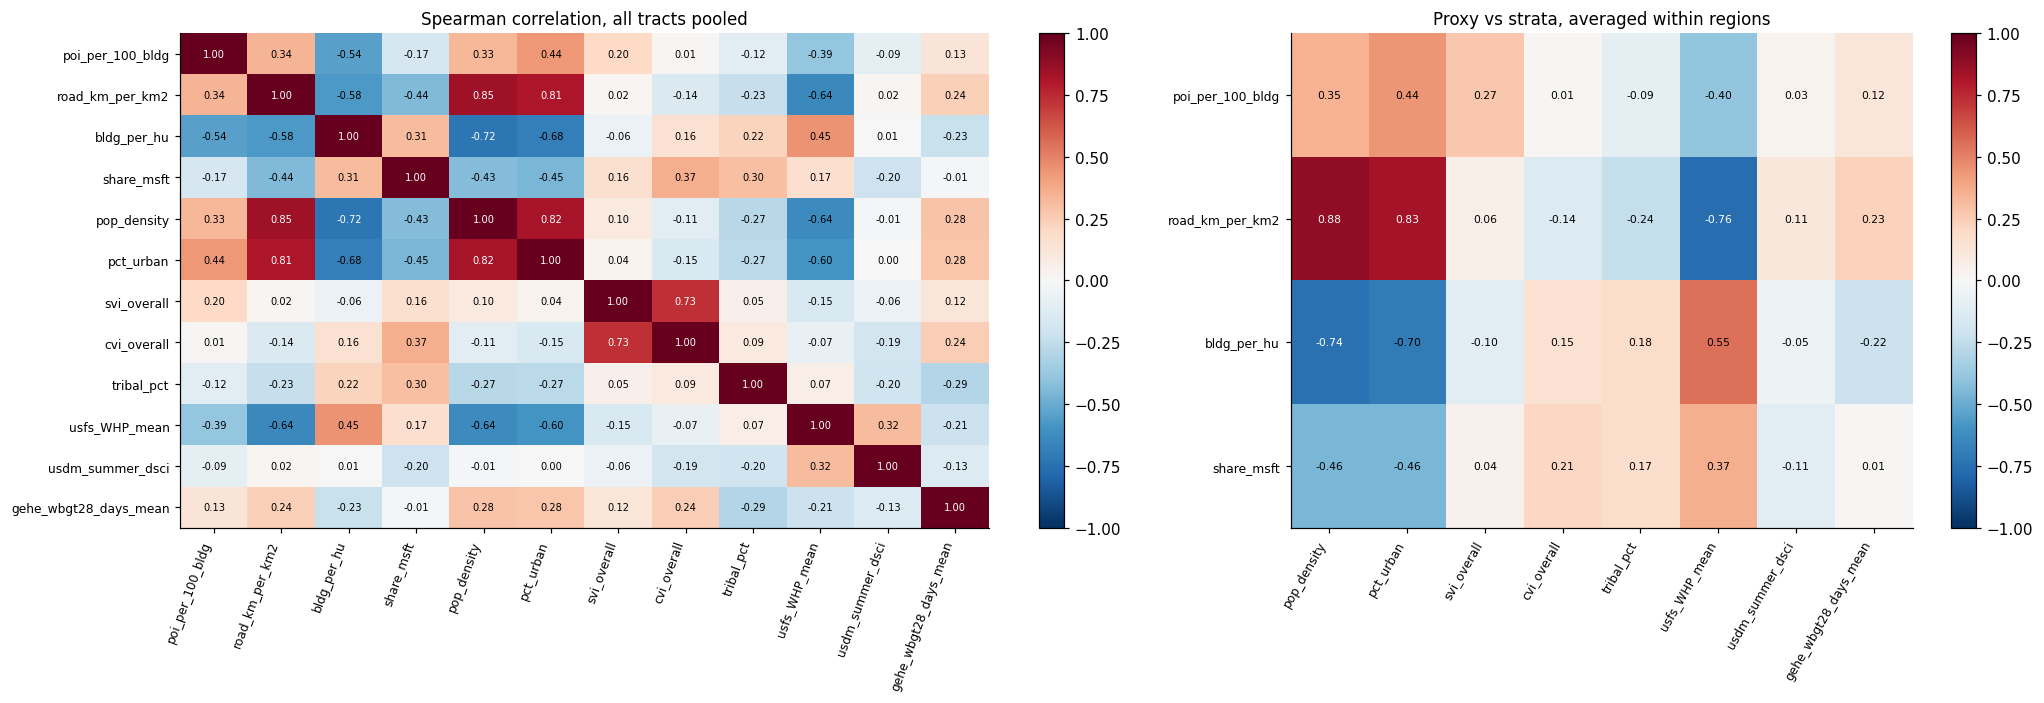

within-region average Spearman:
                  pop_density  pct_urban  svi_overall  cvi_overall  tribal_pct  usfs_WHP_mean  usdm_summer_dsci  gehe_wbgt28_days_mean
poi_per_100_bldg         0.35       0.44         0.27         0.01       -0.09          -0.40              0.03                   0.12
road_km_per_km2          0.88       0.83         0.06        -0.14       -0.24          -0.76              0.11                   0.23
bldg_per_hu             -0.74      -0.70        -0.10         0.15        0.18           0.55             -0.05                  -0.22
share_msft              -0.46      -0.46         0.04         0.21        0.17           0.37             -0.11                   0.01
pooled minus within-region (proxy x hazard):
                  usfs_WHP_mean  usdm_summer_dsci  gehe_wbgt28_days_mean
poi_per_100_bldg           0.01             -0.12                   0.01
road_km_per_km2            0.12             -0.10                   0.00
bldg_per_hu               -0.

In [7]:
cols = ["poi_per_100_bldg", "road_km_per_km2", "bldg_per_hu", "share_msft", "pop_density", "pct_urban", "svi_overall", "cvi_overall", "tribal_pct", "usfs_WHP_mean", "usdm_summer_dsci", "gehe_wbgt28_days_mean"]
cm = df[cols].replace(np.inf, np.nan).corr(method="spearman"); within = pd.concat([df[df.region == r][cols].replace(np.inf, np.nan).corr(method="spearman").loc[cols[:4], cols[4:]] for r in REG]).groupby(level=0).mean().reindex(cols[:4])
fig, ax = plt.subplots(1, 2, figsize=(19, 6.5), gridspec_kw={"width_ratios": [1.3, 1]}); plt.colorbar(heat(ax[0], cm, fs=6.5, rot=70), ax=ax[0]); ax[0].set_title("Spearman correlation, all tracts pooled")
plt.colorbar(heat(ax[1], within, fs=7, rot=60), ax=ax[1]); ax[1].set_title("Proxy vs strata, averaged within regions")
plt.tight_layout(); plt.show(); print("within-region average Spearman:"); print(within.round(2).to_string()); print("pooled minus within-region (proxy x hazard):"); print((cm.loc[cols[:4], cols[9:]] - within[cols[9:]]).round(2).to_string())

**Takeaway:** within regions, road density follows population density (Spearman 0.88) and urban share (0.83), buildings per home falls with density (-0.74) and the Microsoft share falls with it (-0.46). Wildfire hazard potential is also strongly tied to the proxies (-0.76 with road density, +0.55 with buildings per home, +0.37 with Microsoft share), so it behaves like a ruralness measure (wooded, sparse tracts), while drought and heat are weakly related (|rho| 0.23 or less). Pooling regions shifts some correlations: the Microsoft share vs wildfire hazard is 0.20 lower pooled than within regions, and drought correlations shift by 0.10-0.12.